# 02 · Decision trees and gradient boosting

*Level: beginner. Guide Section 6. Code: `models.GBT`.*

**Idea.** A tree asks yes/no questions ("is VDD below −19.4 V?") and returns a number per answer. **Boosting** adds hundreds of small
trees, each correcting what the previous ones got wrong.

In [1]:
from tutorial_utils import *

In [2]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 6, 150))
y = np.sin(x) + 0.5 * (x > 3.5) + 0.15 * rng.normal(size=x.size)

## 1. One split, by hand

A split at threshold $t$ predicts the mean of $y$ on each side. Its loss is the summed squared error of both sides:

$$\text{SSE}(t) = \sum_{x_i \le t}(y_i - \bar y_\text{left})^2 + \sum_{x_i > t}(y_i - \bar y_\text{right})^2 .$$

The tree tries every threshold and keeps the best one.

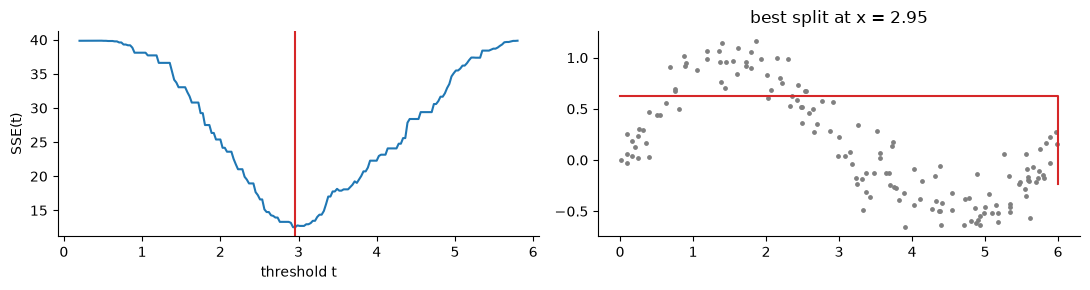

In [3]:
def best_split(x, r):
    order = np.argsort(x); xs, rs = x[order], r[order]
    best = (np.inf, None, None, None)
    for k in range(1, len(xs)):
        if xs[k] == xs[k - 1]:
            continue
        left, right = rs[:k], rs[k:]
        sse = ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()
        if sse < best[0]:
            best = (sse, (xs[k] + xs[k - 1]) / 2, left.mean(), right.mean())
    return best

sse_curve = [(t, ((y[x <= t] - y[x <= t].mean()) ** 2).sum() + ((y[x > t] - y[x > t].mean()) ** 2).sum()) for t in np.linspace(0.2, 5.8, 200)]
sse, t, lo, hi = best_split(x, y)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(*zip(*sse_curve)); ax[0].axvline(t, color="C3"); ax[0].set_xlabel("threshold t"); ax[0].set_ylabel("SSE(t)")
ax[1].scatter(x, y, s=6, color="0.5"); ax[1].step([0, t, 6], [lo, lo, hi], where="post", color="C3"); ax[1].set_title(f"best split at x = {t:.2f}")
plt.tight_layout(); plt.show()

## 2. Boosting, by hand

Start from the mean, $F_0 = \bar y$. Then repeat:
* fit a stump (a one-split tree) $t_m$ to the current **residuals** $r_i = y_i - F_{m-1}(x_i)$;
* add a fraction of it: $F_m = F_{m-1} + \nu\, t_m$.

$\nu$ (the learning rate, 0.05 in our code) makes each tree correct only part of the error, which smooths the result.

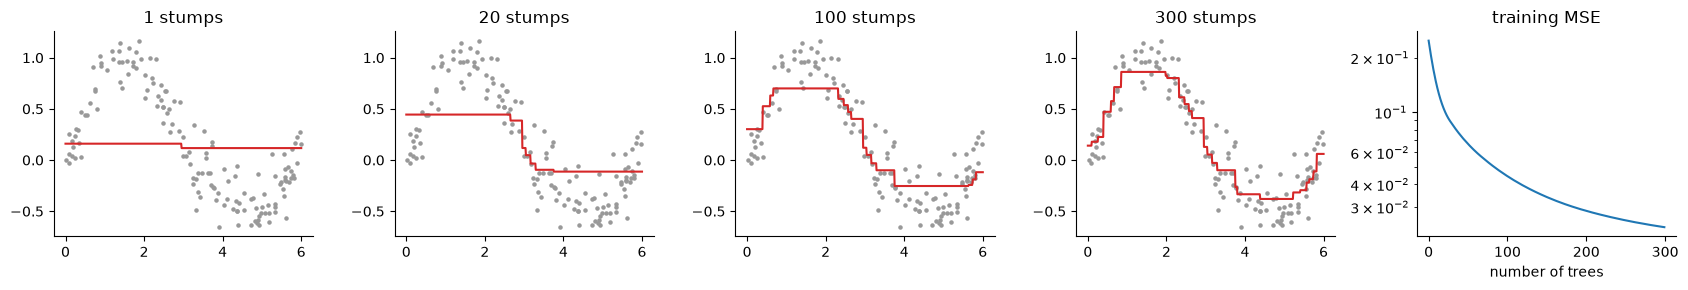

In [4]:
nu, F, snaps, mse = 0.05, np.full_like(y, y.mean()), {}, []
grid = np.linspace(0, 6, 600); Fg = np.full_like(grid, y.mean())
for m_ in range(1, 301):
    _, t, lo, hi = best_split(x, y - F)
    F += nu * np.where(x <= t, lo, hi); Fg += nu * np.where(grid <= t, lo, hi)
    mse.append(np.mean((y - F) ** 2))
    if m_ in (1, 20, 100, 300):
        snaps[m_] = Fg.copy()
fig, ax = plt.subplots(1, 5, figsize=(17, 3))
for a, (m_, g) in zip(ax, snaps.items()):
    a.scatter(x, y, s=5, color="0.6"); a.plot(grid, g, "C3"); a.set_title(f"{m_} stumps")
ax[4].plot(mse); ax[4].set_yscale("log"); ax[4].set_xlabel("number of trees"); ax[4].set_title("training MSE")
plt.tight_layout(); plt.show()

## 3. Error bars from quantiles: the pinball loss

The $\tau$-quantile minimizes the **pinball loss**
$\rho_\tau(u) = \tau u$ for $u \ge 0$ and $(\tau-1)u$ for $u < 0$, where $u = y - q$.

For a Gaussian, the 16 % and 84 % quantiles are μ ∓ σ, so $\hat s = (\hat q_{0.84} - \hat q_{0.16})/2$. Our `GBT` fits these two extra
quantile models per target.

In [5]:
z = np.random.default_rng(1).normal(2.0, 0.5, 5000)
qs = np.linspace(1, 3, 401)
pinball = lambda q, tau: np.mean(np.where(z - q >= 0, tau * (z - q), (tau - 1) * (z - q)))
for tau in (0.16, 0.5, 0.84):
    q_best = qs[np.argmin([pinball(q, tau) for q in qs])]
    print(f"tau = {tau}: pinball minimum at {q_best:.3f};  the data's {tau:.0%} quantile is {np.quantile(z, tau):.3f}")

tau = 0.16: pinball minimum at 1.495;  the data's 16% quantile is 1.498
tau = 0.5: pinball minimum at 1.985;  the data's 50% quantile is 1.987
tau = 0.84: pinball minimum at 2.480;  the data's 84% quantile is 2.481


## 4. On the toy CCD, and its weak point: error bars

The quantile error bars are often too narrow. Below, training is on one scan and testing on a new scan, comparing the raw error bars
with **conformal calibration** (notebook 11), which rescales them using held-out packets.

In [6]:
from ml.calibrate import Conformal
dfa, ca, Ya, ga = toy_scan(120, seed=1); dfb, cb, Yb, gb = toy_scan(60, seed=2)
Xa, _ = data.make_inputs(dfa, ("theta", "trace", "ref"), drop_constant=False)
Xb, _ = data.make_inputs(dfb, ("theta", "trace", "ref"), drop_constant=False)
raw = models.GBT().fit(Xa, Ya)
m, s = raw.predict(Xb)
_ = report("boosted trees, raw error bars", Yb, m, s)
cal = Conformal(lambda: models.GBT()).fit(Xa, Ya, ga)
m2, s2 = cal.predict(Xb)
_ = report("boosted trees, conformal error bars", Yb, m2, s2)

boosted trees, raw error bars            sigma_e:  16.2 % (cover 0.43)   lambda:  28.5 % (cover 0.24)   gain:   9.0 % (cover 0.54)


boosted trees, conformal error bars      sigma_e:  16.2 % (cover 0.62)   lambda:  28.5 % (cover 0.60)   gain:   9.0 % (cover 0.62)


## When to use it

* **Good:** many inputs of different kinds and scales; thresholds and interactions; robust; from ~100 examples.
* **Bad:** error bars (calibrate them); the fit is piecewise constant and flat outside the data, so it is a poor surrogate for optimization.

Next: **03 · Neural networks and deep ensembles.**